In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

In [2]:
df = pd.read_csv('../Dataset/CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


## Soal 1

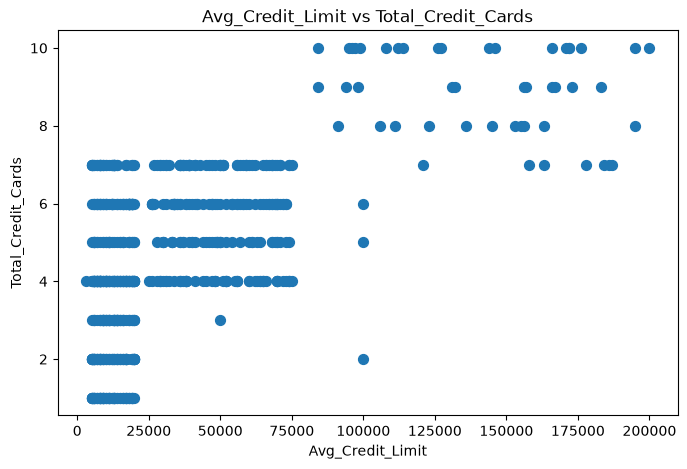

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

In [5]:
df[['Avg_Credit_Limit', 'Total_Credit_Cards']].corr()

,Avg_Credit_Limit,Total_Credit_Cards
Avg_Credit_Limit,1.00000,0.60886
Total_Credit_Cards,0.60886,1.00000


**Jawaban:** sebaran data **tidak linier**. Nilai korelasi hanya 0.609 (R² = 0.371), titik-titik mengumpul
membentuk beberapa kelompok, `Total_Credit_Cards` berupa bilangan bulat 1-10 sehingga grafiknya
berlapis, dan sebaran makin melebar saat `Avg_Credit_Limit` naik.

## Soal 2 - K-Means

In [6]:
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
        'Total_visits_online', 'Total_calls_made']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

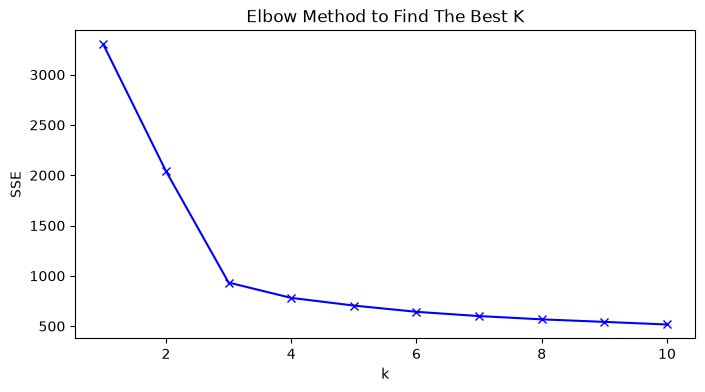

In [7]:
sse = []
K = range(1, 11)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X_scaled)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

**Jawaban:** k terbaik = **3**. SSE turun besar sampai k=3 (3300 -> 2041 -> 933), lalu penurunannya
kecil sekali (k=4 hanya 781). Jadi siku grafik ada di k=3.

In [8]:
cl_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_kmeans = cl_kmeans.fit_predict(X_scaled)

print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 933.0437490000536


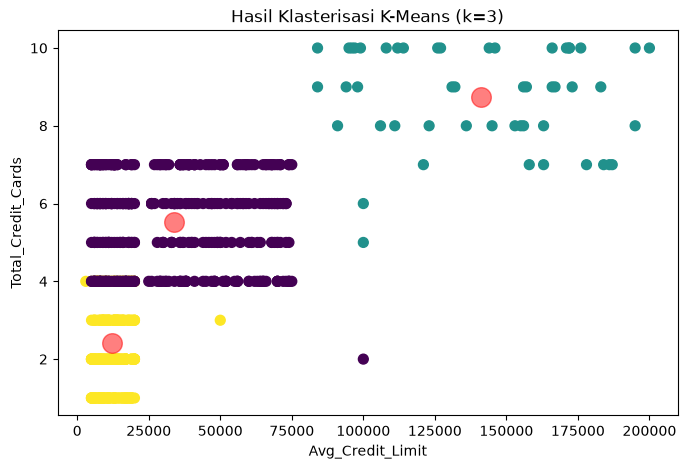

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50, c=y_kmeans)

centers = scaler.inverse_transform(cl_kmeans.cluster_centers_)

plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

In [10]:
df['cluster'] = y_kmeans
df.groupby('cluster')[list(X.columns)].mean()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
cluster,,,,,
0,33782.383420,5.515544,3.489637,0.981865,2.000000
1,141040.000000,8.740000,0.600000,10.900000,1.080000
2,12174.107143,2.410714,0.933036,3.553571,6.870536


In [11]:
print('Silhouette Score:', silhouette_score(X_scaled, y_kmeans))
print('Davies-Bouldin Index:', davies_bouldin_score(X_scaled, y_kmeans))

Silhouette Score: 0.5157182558881063
Davies-Bouldin Index: 0.679698688143959


## Soal 3 - DBSCAN

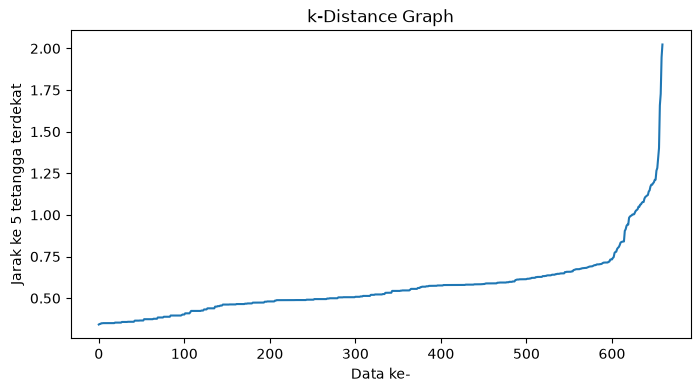

In [12]:
nn = NearestNeighbors(n_neighbors=5).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.xlabel('Data ke-')
plt.ylabel('Jarak ke 5 tetangga terdekat')
plt.title('k-Distance Graph')
plt.show()

**Jawaban:** titik siku (knee) ada di sekitar eps = 0.71. Pada nilai itu semua data masih menyatu
jadi 1 klaster, jadi eps digeser sedikit ke **0.8** dengan `min_samples=5` agar terbentuk 2 klaster
dan noise-nya masih wajar.

In [13]:
dbscan = DBSCAN(eps=0.8, min_samples=5)
y_db = dbscan.fit_predict(X_scaled)

df['cluster_db'] = y_db
print(df['cluster_db'].value_counts())

cluster_db
 0    606
-1     44
 1     10
Name: count, dtype: int64


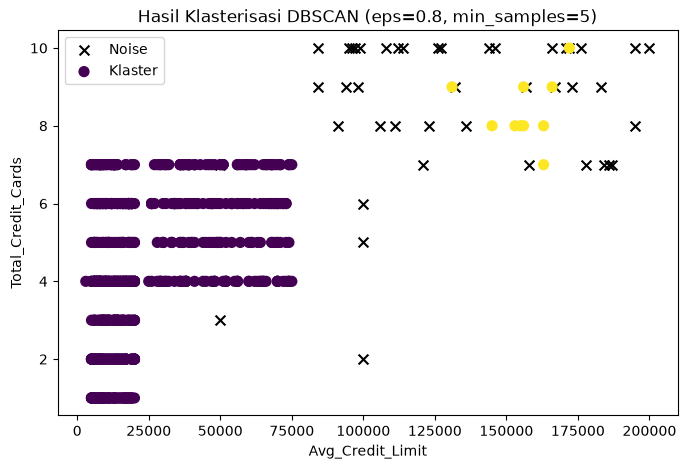

In [14]:
plt.figure(figsize=(8, 5))

# noise (label -1) ditandai terpisah
plt.scatter(df['Avg_Credit_Limit'][y_db == -1], df['Total_Credit_Cards'][y_db == -1],
            s=50, c='black', marker='x', label='Noise')
plt.scatter(df['Avg_Credit_Limit'][y_db != -1], df['Total_Credit_Cards'][y_db != -1],
            s=50, c=y_db[y_db != -1], label='Klaster')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi DBSCAN (eps=0.8, min_samples=5)')
plt.legend()
plt.show()

In [15]:
mask = y_db != -1

print('Silhouette Score:', silhouette_score(X_scaled[mask], y_db[mask]))
print('Davies-Bouldin Index:', davies_bouldin_score(X_scaled[mask], y_db[mask]))

Silhouette Score: 0.5445315927655981
Davies-Bouldin Index: 0.5154197434243778
